# MovieLens Dataset Exploration & Analysis

---

## 1. Loading the MovieLens Dataset Files into Pandas

### What this upcoming code does:
In this first step, we load the complete MovieLens dataset files (`movies.csv`, `ratings.csv`, and `tags.csv`) into Python DataFrames using the `pandas` library.

### Why we are looking at this data:
Before designing recommendation algorithms (such as collaborative filtering, matrix factorization, or content-based models), we need to load and inspect our raw interaction and catalog data:
- **`movies.csv`**: Contains the movie catalog (`movieId`, `title`, `genres`). It tells us what items exist and how they are categorized.
- **`ratings.csv`**: Contains user rating interactions (`userId`, `movieId`, `rating`, `timestamp`). This constitutes the core user-item feedback matrix (over 30 million ratings).
- **`tags.csv`**: Contains user-generated keyword tags (`userId`, `movieId`, `tag`, `timestamp`), representing unstructured user opinions and rich metadata.

Because `ratings.csv` contains tens of millions of records, we specify memory-efficient data types (`int32` for IDs/timestamps, `float32` for ratings). This allows the entire dataset to load quickly while keeping memory usage under 500 MB. We also check for any missing values immediately upon loading to ensure data integrity.

In [1]:
# ==============================================================================
# Cell 1: Load complete CSV files into pandas DataFrames & handle missing values
# ==============================================================================

import sys
import subprocess

# Automatically verify and install required libraries in the active kernel
for pkg_name, import_name in [('seaborn', 'seaborn'), ('scikit-surprise', 'surprise')]:
    try:
        __import__(import_name)
    except ModuleNotFoundError:
        print(f"Installing '{pkg_name}' into active kernel...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg_name])


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual aesthetics for exploratory plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

print("Loading MovieLens CSV files into pandas DataFrames...")

# 1. Load movies.csv: Movie catalog with title and genre information
movies_df = pd.read_csv('movies.csv')

# 2. Load ratings.csv: Optimized data types to reduce memory footprint (~488 MB instead of >1 GB)
ratings_df = pd.read_csv(
    'ratings.csv',
    dtype={
        'userId': 'int32',
        'movieId': 'int32',
        'rating': 'float32',
        'timestamp': 'int32'
    }
)

# 3. Load tags.csv: User-generated descriptive tags
tags_df = pd.read_csv(
    'tags.csv',
    dtype={
        'userId': 'int32',
        'movieId': 'int32',
        'tag': 'str',
        'timestamp': 'int32'
    }
)

# Handle missing values: Inspect null counts in each dataset
print("\n--- Missing Values Check ---")
print("movies_df missing values:")
print(movies_df.isna().sum())

print("\nratings_df missing values:")
print(ratings_df.isna().sum())

print("\ntags_df missing values (before cleaning):")
print(tags_df.isna().sum())

# Clean missing values: fill 17 missing tags in tags.csv with an empty string
tags_df['tag'] = tags_df['tag'].fillna('')

print("\nMissing values handled successfully!")
print(f"- movies_df:  {movies_df.shape[0]:,} rows x {movies_df.shape[1]} columns")
print(f"- ratings_df: {ratings_df.shape[0]:,} rows x {ratings_df.shape[1]} columns")
print(f"- tags_df:    {tags_df.shape[0]:,} rows x {tags_df.shape[1]} columns")

Loading MovieLens CSV files into pandas DataFrames...



--- Missing Values Check ---
movies_df missing values:
movieId    0
title      0
genres     0
dtype: int64

ratings_df missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

tags_df missing values (before cleaning):
userId        0
movieId       0
tag          17
timestamp     0
dtype: int64

Missing values handled successfully!
- movies_df:  87,585 rows x 3 columns
- ratings_df: 32,000,204 rows x 4 columns
- tags_df:    2,000,072 rows x 4 columns


---

## 2. Data Cleaning and Summary Statistics

### What this upcoming code does:
In this section, we verify the clean state of our loaded datasets, inspect the column structures and non-null counts using `df.info()`, and produce a simple one-line statistical summary for each dataset using `df.describe(include='all')`.

### Why we are looking at this data:
Data cleaning and summary statistics are critical health checks before building machine learning models or recommendation pipelines:
- **`df.info()`**: Confirms that every column has the expected data type, that no unintended null values remain, and reports the exact memory footprint in RAM.
- **`df.describe(include='all')`**: Produces a comprehensive statistical snapshot across both numerical and categorical variables in a single line. It shows:
  - **Count & Unique**: How many unique users, movies, and tags exist, which helps gauge the sparsity of the user-item interaction matrix.
  - **Mean, Min, Max & Quartiles**: Verifies the rating scale boundaries (0.5 to 5.0), the central tendency of ratings (~3.54), and flags any potential outliers or corrupt records.
  - **Top & Freq**: Highlights the most frequent genres or tags across the catalog.

In [2]:
# ==============================================================================
# Cell 2: Check missing values using df.info() & one-line df.describe(include='all')
# ==============================================================================

# 1. Structural inspection & missing values verification using df.info()
print("=" * 60)
print("1. MOVIES DATASET: movies_df.info()")
print("=" * 60)
movies_df.info()

print("\n" + "=" * 60)
print("2. RATINGS DATASET: ratings_df.info()")
print("=" * 60)
ratings_df.info()

print("\n" + "=" * 60)
print("3. TAGS DATASET: tags_df.info()")
print("=" * 60)
tags_df.info()

# 2. Simple one-line statistical summaries using df.describe(include='all')
print("\n" + "=" * 60)
print("ONE-LINE SUMMARY: movies_df.describe(include='all')")
print("=" * 60)
display(movies_df.describe(include='all'))

print("\n" + "=" * 60)
print("ONE-LINE SUMMARY: ratings_df.describe(include='all')")
print("=" * 60)
display(ratings_df.describe(include='all'))

print("\n" + "=" * 60)
print("ONE-LINE SUMMARY: tags_df.describe(include='all')")
print("=" * 60)
display(tags_df.describe(include='all'))

1. MOVIES DATASET: movies_df.info()
<class 'pandas.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   movieId  87585 non-null  int64
 1   title    87585 non-null  str  
 2   genres   87585 non-null  str  
dtypes: int64(1), str(2)
memory usage: 5.2 MB

2. RATINGS DATASET: ratings_df.info()
<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int32  
 1   movieId    int32  
 2   rating     float32
 3   timestamp  int32  
dtypes: float32(1), int32(3)
memory usage: 488.3 MB

3. TAGS DATASET: tags_df.info()
<class 'pandas.DataFrame'>
RangeIndex: 2000072 entries, 0 to 2000071
Data columns (total 4 columns):
 #   Column     Dtype
---  ------     -----
 0   userId     int32
 1   movieId    int32
 2   tag        str  
 3   timestamp  int32
dtypes: int32(3), str(1)
memory usage

,movieId,title,genres
count,87585.000000,87585,87585
unique,NaN,87382,1798
top,NaN,Alone (2020),Drama
freq,NaN,4,12443
mean,157651.365519,NaN,NaN
std,79013.402099,NaN,NaN
min,1.000000,NaN,NaN
25%,112657.000000,NaN,NaN
50%,165741.000000,NaN,NaN
75%,213203.000000,NaN,NaN



ONE-LINE SUMMARY: ratings_df.describe(include='all')


,userId,movieId,rating,timestamp
count,3.200020e+07,3.200020e+07,3.200020e+07,3.200020e+07
mean,1.002785e+05,2.931861e+04,3.540396e+00,1.275241e+09
std,5.794905e+04,5.095816e+04,1.058986e+00,2.561630e+08
min,1.000000e+00,1.000000e+00,5.000000e-01,7.896520e+08
25%,5.005300e+04,1.233000e+03,3.000000e+00,1.051012e+09
50%,1.002970e+05,3.452000e+03,3.500000e+00,1.272622e+09
75%,1.504510e+05,4.419900e+04,4.000000e+00,1.503158e+09
max,2.009480e+05,2.927570e+05,5.000000e+00,1.697164e+09



ONE-LINE SUMMARY: tags_df.describe(include='all')


,userId,movieId,tag,timestamp
count,2.000072e+06,2.000072e+06,2000072,2.000072e+06
unique,NaN,NaN,140980,NaN
top,NaN,NaN,sci-fi,NaN
freq,NaN,NaN,10996,NaN
mean,8.192859e+04,7.189326e+04,NaN,1.528914e+09
std,3.810650e+04,7.480379e+04,NaN,1.290835e+08
min,2.200000e+01,1.000000e+00,NaN,1.135429e+09
25%,6.841300e+04,4.011000e+03,NaN,1.473615e+09
50%,7.821300e+04,5.232800e+04,NaN,1.574071e+09
75%,1.036980e+05,1.222940e+05,NaN,1.614740e+09


---

## 3. Exploratory Data Analysis (EDA) and Rating Patterns

### What this upcoming code does:
In this section, we generate three simple, insightful plots using `matplotlib` and `seaborn`:
1. **Plot 1: Bar chart showing the distribution of star ratings (0.5 to 5.0).**
2. **Plot 2: Histogram showing how many ratings each user gave.**
3. **Plot 3: Bar chart showing the most popular movie genres.**

### Why seeing rating patterns helps us build better recommendations:
- **Understanding Rating Bias & Skewness (Plot 1)**:
  Users do not rate movies uniformly. Most ratings tend to cluster around 3.0, 4.0, and 5.0 (users naturally choose to watch movies they expect to enjoy, and prefer whole-star ratings over half-stars). Knowing this distribution tells us we must apply baseline predictors (subtracting user and item mean biases) in collaborative filtering algorithms to prevent recommendations from simply favoring movies with higher average exposure.
- **Diagnosing the Long-Tail & Cold-Start Problem (Plot 2)**:
  The user rating histogram reveals a heavy right-skewed "long tail" (power law distribution): a handful of power users rate thousands of movies, while the vast majority rate only 20 to 100 movies. Understanding this sparsity helps us design fallback strategies for cold-start users (e.g., popular or genre-based recommendations).
- **Catalog Diversity & Content Coverage (Plot 3)**:
  Analyzing genre frequencies shows which categories dominate the catalog (e.g., Drama, Comedy, Thriller) and which are niche (e.g., Film-Noir, IMAX). Recommenders that ignore genre distribution risk succumbing to popularity bias and offering monotonous recommendations.

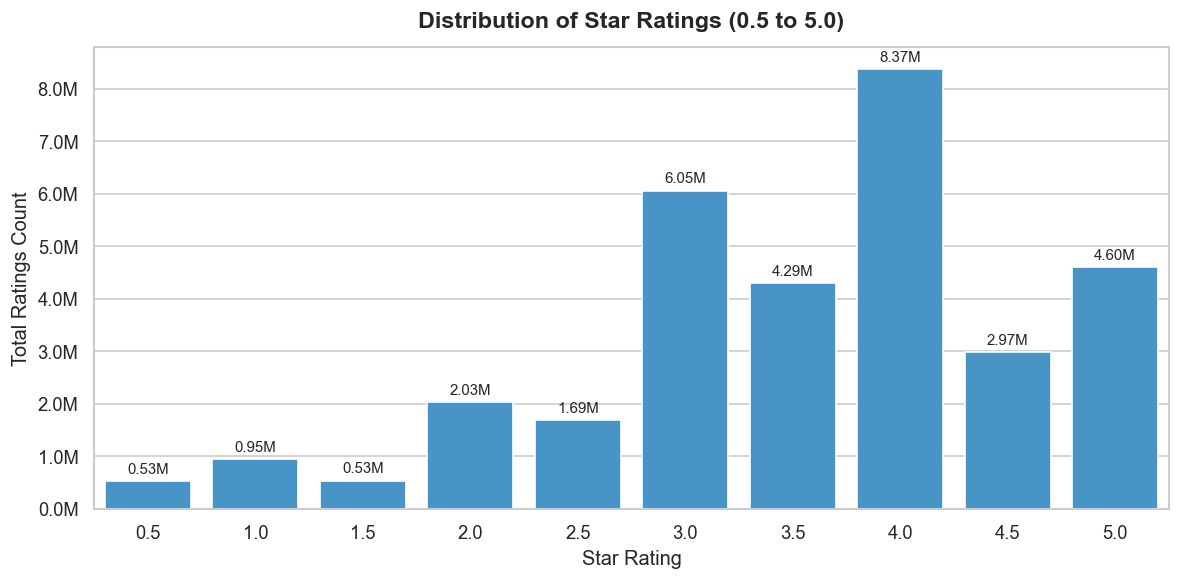

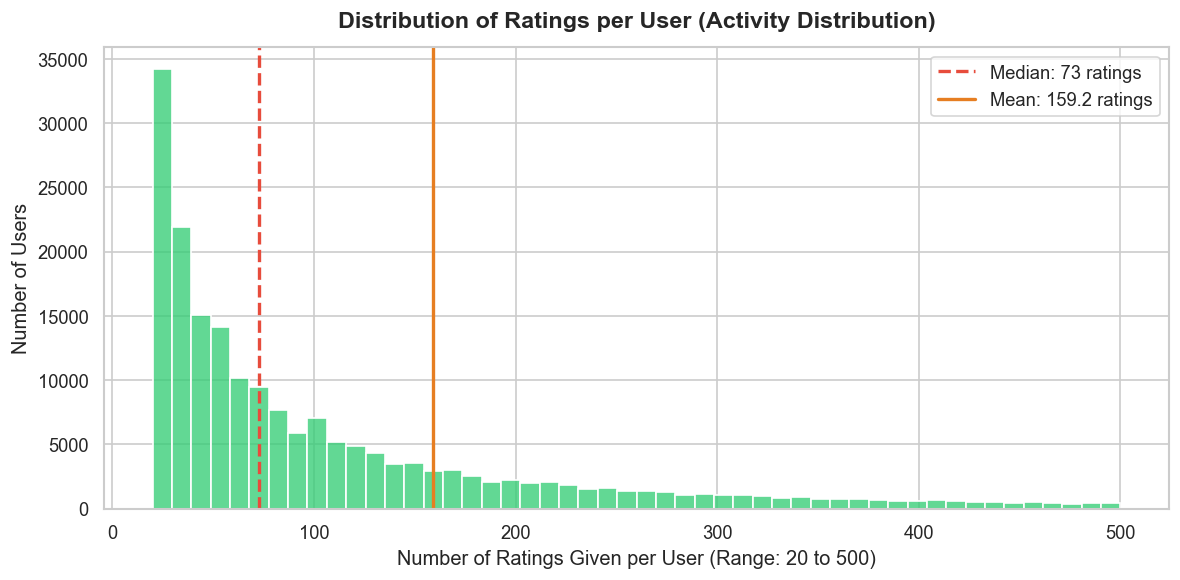

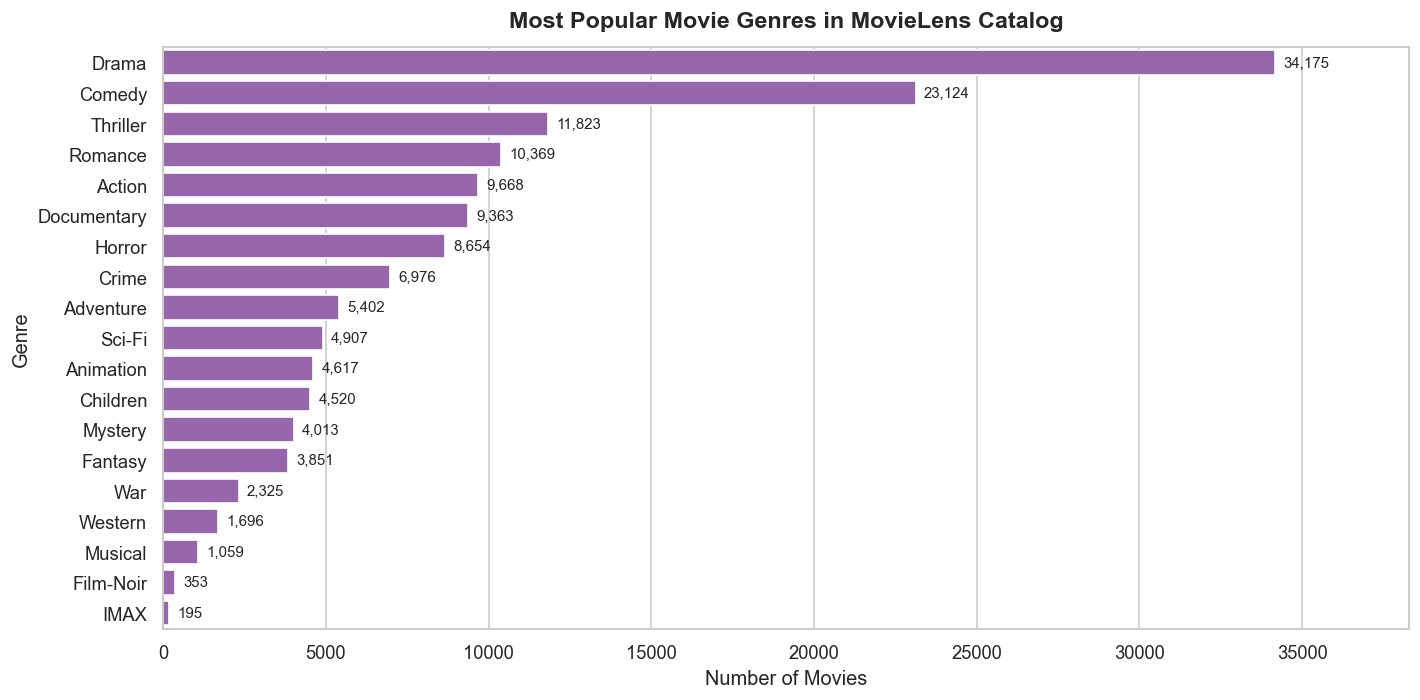

In [3]:
# ==============================================================================
# Cell 3: Generate 3 simple matplotlib/seaborn EDA plots
# ==============================================================================

# ------------------------------------------------------------------------------
# Plot 1: Bar chart showing the distribution of star ratings (0.5 to 5.0)
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))
rating_counts = ratings_df['rating'].value_counts().sort_index()

ax1 = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    color='#3498db'
)

plt.title('Distribution of Star Ratings (0.5 to 5.0)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Star Rating', fontsize=12)
plt.ylabel('Total Ratings Count', fontsize=12)

# Format y-axis with millions (M) for clear readability
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x*1e-6:.1f}M"))

# Annotate each bar with the count
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(
        f"{height*1e-6:.2f}M",
        (p.get_x() + p.get_width() / 2., height),
        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points'
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 2: Histogram showing how many ratings each user gave
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 5))
user_rating_counts = ratings_df.groupby('userId').size()

# Plot histogram showing user rating activity (focusing on the 20-500 range where >95% of users sit)
sns.histplot(
    user_rating_counts,
    bins=50,
    binrange=(20, 500),
    color='#2ecc71',
    edgecolor='white'
)

plt.title('Distribution of Ratings per User (Activity Distribution)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Ratings Given per User (Range: 20 to 500)', fontsize=12)
plt.ylabel('Number of Users', fontsize=12)
plt.axvline(user_rating_counts.median(), color='#e74c3c', linestyle='--', linewidth=2, label=f'Median: {user_rating_counts.median():.0f} ratings')
plt.axvline(user_rating_counts.mean(), color='#e67e22', linestyle='-', linewidth=2, label=f'Mean: {user_rating_counts.mean():.1f} ratings')
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Plot 3: Bar chart showing the most popular movie genres
# ------------------------------------------------------------------------------
plt.figure(figsize=(12, 6))

# Split '|'-separated genres and count individual occurrences across the movie catalog
genre_series = movies_df['genres'].str.split('|').explode()
# Filter out movies without listed genres for clean visualization
genre_counts = genre_series[genre_series != '(no genres listed)'].value_counts()

ax3 = sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,
    color='#9b59b6'
)

plt.title('Most Popular Movie Genres in MovieLens Catalog', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Number of Movies', fontsize=12)
plt.ylabel('Genre', fontsize=12)

# Annotate each bar with the exact movie count
for p in ax3.patches:
    width = p.get_height() if hasattr(p, 'get_height') and p.get_height() > p.get_width() else p.get_width()
    ax3.annotate(
        f"{int(width):,}",
        (width, p.get_y() + p.get_height() / 2.),
        ha='left', va='center', fontsize=9, xytext=(5, 0), textcoords='offset points'
    )

plt.xlim(0, max(genre_counts.values) * 1.12)
plt.tight_layout()
plt.show()